# Import Toolkits  

In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import plotly.express as px

# Import the data set 

In [ ]:
df = pd.read_csv("/kaggle/input/house-prices-advanced-regression-techniques/train.csv")
df.head(10)

# Getting a first look at the data

In [ ]:
df.info()

In [ ]:
df.describe()

### <span style="color:red">First insight:</span> If the values in the columns are normally distributed, the closer the mean is to the median (the 50th percentile or 2nd quartile), the closer the data is to a normal distribution.

### <span style="color:red">Insight:</span> Most houses in this dataset are priced between 129K and 214K, which corresponds to the **interquartile range (between the 1st and 3rd quartile)**.


# Pre_processing


## Missing values

### Getting the columns with more than 50% NaN values


In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

### Drop the columns that have a ratio of NaN values higher than 50%.


In [ ]:
df.drop(columns = ['MasVnrType','Fence','Alley','MiscFeature','PoolQC'],inplace = True )

In [ ]:

df.shape

In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

### Let's first examine the `FireplaceQu` column and try to fill the missing values by referring to the Dataset Description.


### The `FireplaceQu` column (Fireplace Quality) is directly related to the `Fireplaces` column (Number of Fireplaces).


### Let's create a copy of these two columns to work on, so we don't alter the original DataFrame.

In [ ]:
fire_mask = []
for i in df.columns:
    if i.startswith("Fire"):
        fire_mask.append(i)

fire_mask = df[fire_mask]

In [ ]:
fire_mask

In [ ]:
fire_mask[fire_mask['FireplaceQu'].isna()]

In [ ]:
fire_mask[fire_mask['FireplaceQu'].isna()]['Fireplaces'].sum()

### <span style="color:red">Insight:</span> All NaN values occur because there are **0 fireplaces** in those houses.


In [ ]:

fire_mask['FireplaceQu'].unique()

### To avoid rewriting the code for filling missing values, we'll create a function that fills them using a specified impute value.


In [ ]:
def fill_missing(column , value ):
    if column in df.columns :
        df.fillna({ column : value } , inplace = True)
        print(f"Missing values in column {column} is replaced by {value}")
    else :
        print(f"column {column} does not exist")

In [ ]:
fill_missing('FireplaceQu', "Zero")


In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

### The following columns have the **same percentage of missing values**, which indicates a relationship between their missing entries:

| Column Name   | % of Missing Values |
|----------------|---------------------|
| GarageFinish   | 5.547945% |
| GarageQual     | 5.547945% |
| GarageCond     | 5.547945% |
| GarageYrBlt    | 5.547945% |
| GarageType     | 5.547945% |


### We'll apply the same approach as we did for the fireplaces.


In [ ]:
garage_mask = []
for i in df.columns :
    if i.startswith("Garage"):
        garage_mask.append(i)
garage_mask
    

In [ ]:
garage_mask= df[garage_mask]
garage_mask

In [ ]:
garage_mask[garage_mask["GarageType"].isna()]

### Making sure that all values in these columns — `GarageCars` and `GarageArea` — are zeros.


In [ ]:
garage_mask[garage_mask["GarageType"].isna()][['GarageCars','GarageArea']].sum()

### <span style="color:red">Insight:</span> Based on the Dataset Description:
- **`GarageType`**: Garage location  
- **`GarageYrBlt`**: Year the garage was built  
- **`GarageFinish`**: Interior finish of the garage  
- **`GarageCars`**: Size of the garage in car capacity  
- **`GarageArea`**: Size of the garage in square feet  
- **`GarageQual`**: Garage quality  
- **`GarageCond`**: Garage condition  

This indicates that the missing values in these columns exist because **those houses do not have a garage**.

In [ ]:
garage_mask.info()

In [ ]:
fill_missing('GarageType', "NF")
fill_missing('GarageFinish', "NF")
fill_missing('GarageQual', "NF")
fill_missing('GarageCond', "NF")
fill_missing('GarageYrBlt', 0)
fill_missing('GarageCars', 0)
fill_missing('GarageArea', 0)

In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

### We'll now try to understand the following columns and their missing values:

| Column Name   | % of Missing Values |
|----------------|---------------------|
| BsmtQual       | 2.53% |
| BsmtFinType1   | 2.53% |
| BsmtCond       | 2.53% |
| BsmtExposure   | 2.60% |
| BsmtFinType2   | 2.60% |


In [ ]:
Bsmnt_mask = []
for i in df.columns :
    if i.startswith("Bsmt"):
        Bsmnt_mask.append(i)
Bsmnt_mask

In [ ]:
Bsmnt_mask= df[Bsmnt_mask]
Bsmnt_mask

In [ ]:
Bsmnt_mask.isna().sum()

### Only the `BsmtExposure` column contains NaN values, while the other basement-related columns are complete.


In [ ]:
Bsmnt_mask[(Bsmnt_mask['BsmtExposure'].isna()) & (Bsmnt_mask['BsmtCond'].isna()== False)]

### Only this column’s missing value is not related to the others, so we'll fill it with the mode since its data type is **object (string)**.



In [ ]:
BsmtExposure_mode = df['BsmtExposure'].mode()[0]
BsmtExposure_mode

In [ ]:
df.loc[948 , 'BsmtExposure']= BsmtExposure_mode

### Only the `BsmtFinType2` column contains NaN values, while the other basement-related columns are complete.

In [ ]:
Bsmnt_mask[(Bsmnt_mask['BsmtFinType2'].isna()) & (Bsmnt_mask['BsmtCond'].isna()== False)]

### Only this column’s missing value is not related to the others, so we'll fill it with the mode since its data type is **object (string)**.


In [ ]:
BsmtFinType2_mode = df['BsmtFinType2'].mode()[0]
df.loc[332 , 'BsmtFinType2']= BsmtFinType2_mode

In [ ]:
df.loc[332 , 'BsmtFinType2']

### Now, I'll update the masked DataFrame.


In [ ]:
Bsmnt_mask = []
for i in df.columns :
    if i.startswith("Bsmt"):
        Bsmnt_mask.append(i)

Bsmnt_mask= df[Bsmnt_mask]
Bsmnt_mask.isna().sum()

In [ ]:
Bsmnt_mask[Bsmnt_mask["BsmtQual"].isna()][['BsmtFinSF1','BsmtFinSF2']].sum()

### <span style="color:red">Insight:</span> Based on the Dataset Description:

- **`BsmtQual`**: Height of the basement  
- **`BsmtCond`**: General condition of the basement  
- **`BsmtExposure`**: Walkout or garden level basement walls  
- **`BsmtFinType1`**: Quality of basement finished area  
- **`BsmtFinSF1`**: Type 1 finished square feet  
- **`BsmtFinType2`**: Quality of second finished area (if present)  
- **`BsmtFinSF2`**: Type 2 finished square feet  
- **`BsmtUnfSF`**: Unfinished square feet of basement area  

This indicates that the missing values in these columns exist because **those houses do not have a basement**.


In [ ]:
Bsmnt_mask.info()

In [ ]:
fill_missing('BsmtQual', "NF")
fill_missing('BsmtCond', "NF")
fill_missing('BsmtExposure', "NF")
fill_missing('BsmtFinType1', "NF")
fill_missing('BsmtFinType2', "NF")


### Now, I’ll handle the individual columns separately.

In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

In [ ]:
df[df['Electrical'].isna()]

In [ ]:
df['Electrical'].info()

### <span style="color:red">Insight:</span> There is only one missing value, so we'll fill it with the mode since the data type is **object (string)**.


In [ ]:
Electrical_mode = df['Electrical'].mode()[0]
df.loc[1379 , 'Electrical']= Electrical_mode

In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

In [ ]:
df['MasVnrArea'].describe()

In [ ]:
sns.histplot(df, x = 'MasVnrArea', kde= True)

In [ ]:
(df['MasVnrArea'].value_counts()/len(df))*100

### <span style="color:red">Insight:</span> The percentage of zeros in this column is over **58%**, so we'll fill the **8 missing values** with **0 (the median)**.


In [ ]:
df['MasVnrArea'].fillna(df['MasVnrArea'].median(), inplace= True)

In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

In [ ]:
Lot_mask = []
for i in df.columns :
    if i.startswith("Lot"):
        Lot_mask.append(i)

Lot_mask= df[Lot_mask]
Lot_mask.isna().sum()

In [ ]:
Lot_mask[Lot_mask['LotFrontage'].isna()]

In [ ]:
sns.histplot(df, x = 'LotFrontage', kde= True)

### <span style="color:red">Insight:</span> Based on the Dataset Description:

- **`LotFrontage`**: Linear feet of street connected to the property  
- **`LotArea`**: Lot size in square feet  
- **`LotShape`**: General shape of the property  

There is no reliable way to determine the `LotFrontage` value, so we'll fill it with the **mean**, since it is **normally distributed**.


In [ ]:
LotFrontage_mean = df['LotFrontage'].mean()
fill_missing('LotFrontage', LotFrontage_mean)

In [ ]:
(df.isna().sum().sort_values().tail(10) / len(df)) * 100

### Finally, there are no missing values remaining in the dataset.

## Analysis

In [ ]:
df.info()


### I'll perform feature engineering by replacing the `YearBuilt` column with a new column called `Age` to make the data easier to interpret.


In [ ]:
df['YearBuilt'].corr(df['SalePrice'])

In [ ]:
df["Age"]= 2025 -df['YearBuilt']

In [ ]:
df.drop(columns = ['YearBuilt'], inplace = True)

In [ ]:
df['Age'].corr(df['SalePrice'])

### I'll plot a heatmap to visualize the correlation among all numerical features in the dataset.


In [ ]:
num_columns = df.select_dtypes(exclude = 'object')
num_columns

In [ ]:
corr= num_columns.corr()

In [ ]:
plt.figure(figsize = (45,45))
sns.heatmap(corr,annot= True, fmt ='.1g',cmap = 'Blues')

In [ ]:
corr = num_columns.corr()['SalePrice'].drop('SalePrice').sort_values(ascending=False)

fig = px.bar(
    x=corr.index,
    y=corr.values,
    title="Correlation with SalePrice",
    labels={'x': 'Features', 'y': 'Correlation'},
    color=corr.values,
    color_continuous_scale='RdYlGn'
)

fig.show()


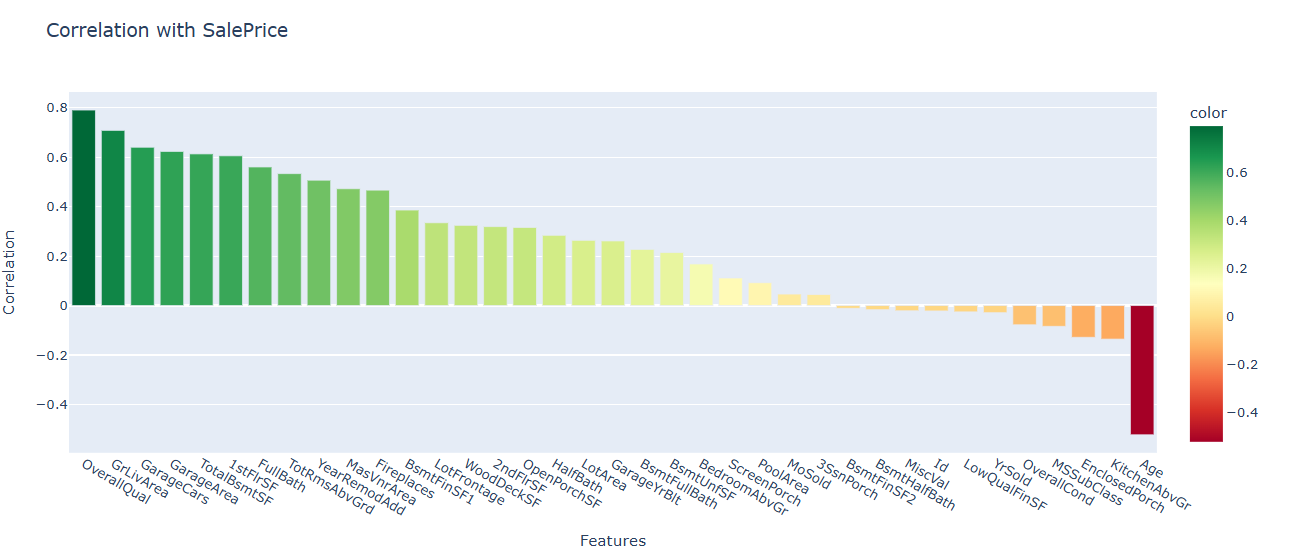
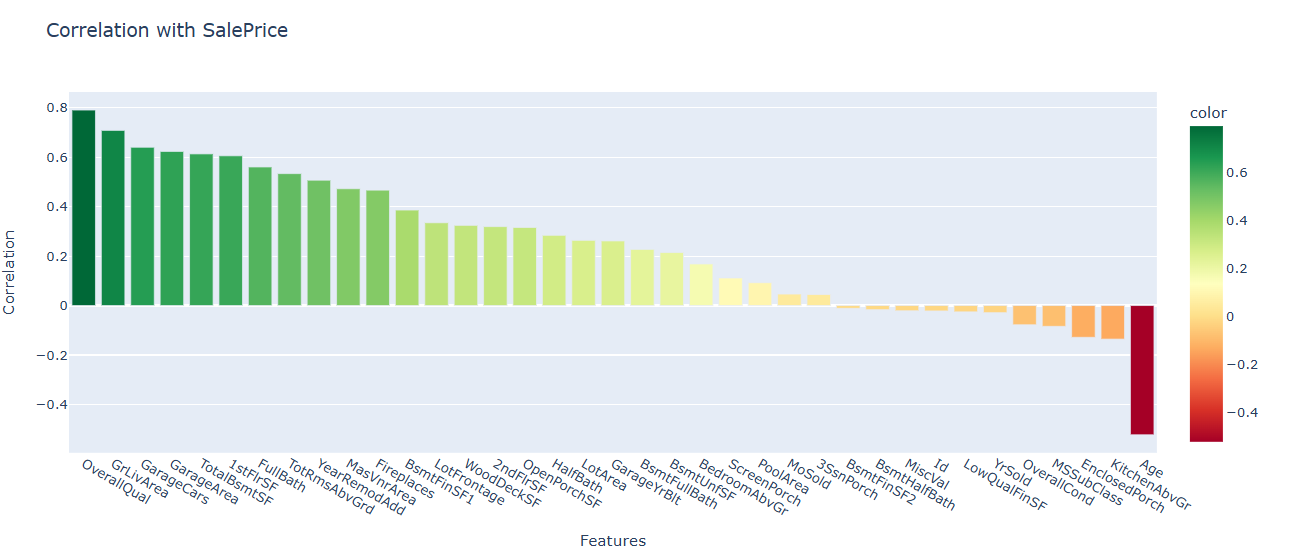

### <span style="color:red">**Insight**:</span>  
The correlation analysis with `SalePrice` reveals that **Overall Quality (`OverallQual`)** and **Above Ground Living Area (`GrLivArea`)** are the most influential features, both showing strong positive correlations with sale price. This indicates that houses with better overall quality and larger living areas tend to sell for significantly higher prices.  

Garage-related features (`GarageCars`, `GarageArea`), total basement area (`TotalBsmtSF`), and the number of full bathrooms (`FullBath`) also demonstrate moderate positive correlations, suggesting they contribute meaningfully to property value.  

On the other hand, **`Age`** shows a **negative correlation**, meaning newer houses tend to have higher sale prices, while **`KitchenAbvGr`** (number of kitchens above ground) also correlates negatively—likely because multiple kitchens are uncommon and may indicate non-standard or older layouts.  
